## Preparar la nube

Primero cargamos el escaneo y revisamos sus dimensiones para confirmar que las coordenadas estén en la escala esperada. Después reducimos la cantidad de puntos con vóxeles: así el análisis es más manejable, aunque se pierde algo de detalle. La nube original se conserva para el archivo final.

In [4]:
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Configuración de archivos
ARCHIVO_ENTRADA = "FARO_Scan_Full_Sub1_down3_with_normals.ply"
ARCHIVO_SALIDA = "FARO_Scan_Segmentado_Final.ply"
VOXEL_SIZE = 0.08  # Tamaño de vóxel en metros para agilizar el clustering

print(f"Cargando {ARCHIVO_ENTRADA}...")
pcd_orig = o3d.io.read_point_cloud(ARCHIVO_ENTRADA)
pts_orig = np.asarray(pcd_orig.points)

print(f"Total de puntos originales: {len(pts_orig):,}")
print(f"Rango X: [{pts_orig[:,0].min():.2f}, {pts_orig[:,0].max():.2f}]")
print(f"Rango Y: [{pts_orig[:,1].min():.2f}, {pts_orig[:,1].max():.2f}]")
print(f"Rango Z: [{pts_orig[:,2].min():.2f}, {pts_orig[:,2].max():.2f}]")

# Las normales vienen en el PLY; las normalizamos antes de usarlas para filtrar superficies.
pcd_orig.normalize_normals()

# Trabajamos con una copia más ligera; la nube completa queda intacta para exportarla luego.
pcd_down = pcd_orig.voxel_down_sample(voxel_size=VOXEL_SIZE)
puntos = np.asarray(pcd_down.points)
normales = np.asarray(pcd_down.normals)
colores = np.asarray(pcd_down.colors)
n_puntos = len(puntos)

print(f"Puntos en nube de trabajo (Voxel Downsampled): {n_puntos:,}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Cargando FARO_Scan_Full_Sub1_down3_with_normals.ply...
Total de puntos originales: 1,647,021
Rango X: [-2.58, 28.80]
Rango Y: [-11.87, 22.99]
Rango Z: [-2.31, 14.46]
Puntos en nube de trabajo (Voxel Downsampled): 460,789


## Buscar superficies horizontales

Las superficies horizontales suelen tener una normal alineada con el eje Z. Usamos esa orientación para seleccionar candidatos y RANSAC para encontrar los planos grandes. La altura respecto a la mediana de la escena sirve como una regla sencilla para distinguir el piso de las superficies superiores; en escenas con varias plataformas puede no coincidir con la clase real.

In [5]:
# Empezamos sin clasificar; cada etapa asignará una etiqueta y un color a sus puntos.
etiquetas = np.full(n_puntos, -1, dtype=int)
colores_seg = np.zeros((n_puntos, 3))

DIST_PLANO_HORIZ = 0.10  # Tolerancia de grosor para piso y techo

# Filtrar candidatos horizontales usando la componente Z de la normal (nz)
indices_disp = np.where(etiquetas == -1)[0]
mask_horiz = np.abs(normales[indices_disp, 2]) > 0.85
idx_horiz = indices_disp[mask_horiz]
pcd_horiz = pcd_down.select_by_index(idx_horiz)

# RANSAC devuelve índices locales al subconjunto; luego los convertimos a índices globales.
idx_local = np.arange(len(idx_horiz))
z_mediana_global = np.median(puntos[:, 2])

for i in range(3):  # Buscar hasta 3 planos horizontales (Piso, Techo, Plataformas)
    if len(idx_local) < 500:
        break
    sub_pcd = pcd_horiz.select_by_index(idx_local)
    modelo, inliers = sub_pcd.segment_plane(
        distance_threshold=DIST_PLANO_HORIZ, ransac_n=3, num_iterations=1000
    )
    if len(inliers) < 500:
        break

    idx_global_plano = idx_horiz[idx_local[inliers]]
    z_medio = np.mean(puntos[idx_global_plano, 2])

    # La altura es una regla práctica; puede fallar si hay varias plataformas o desniveles.
    if z_medio < z_mediana_global:
        etiquetas[idx_global_plano] = 1  # Clase 1: Piso
        colores_seg[idx_global_plano] = [0.0, 0.0, 0.95]  # Azul intenso
        print(f"Plano {i+1} -> PISO ({len(idx_global_plano):,} pts | Z medio = {z_medio:.2f})")
    else:
        etiquetas[idx_global_plano] = 2  # Clase 2: Techo
        colores_seg[idx_global_plano] = [0.0, 0.80, 0.90] # Cian / Celeste
        print(f"Plano {i+1} -> TECHO ({len(idx_global_plano):,} pts | Z medio = {z_medio:.2f})")

    idx_local = np.setdiff1d(idx_local, inliers)

Plano 1 -> PISO (86,895 pts | Z medio = -1.55)
Plano 2 -> PISO (31,011 pts | Z medio = -1.71)
Plano 3 -> PISO (27,213 pts | Z medio = -1.70)


## Encontrar paredes y fachadas

En una pared, la normal apunta aproximadamente en dirección horizontal, así que su componente Z suele ser pequeña. Con ese filtro reducimos los candidatos y RANSAC va extrayendo los planos grandes uno por uno. Los umbrales de puntos mínimos y distancia dependen de la densidad y la escala del escaneo.

In [6]:
DIST_PLANO_VERT = 0.12
MAX_PAREDES = 6

# No volvemos a procesar puntos que ya quedaron asignados como piso o techo.
indices_disp = np.where(etiquetas == -1)[0]
mask_vert = np.abs(normales[indices_disp, 2]) < 0.25
idx_vert = indices_disp[mask_vert]
pcd_vert = pcd_down.select_by_index(idx_vert)

idx_local_v = np.arange(len(idx_vert))

for i in range(MAX_PAREDES):
    if len(idx_local_v) < 800:
        break
    sub_pcd = pcd_vert.select_by_index(idx_local_v)
    modelo, inliers = sub_pcd.segment_plane(
        distance_threshold=DIST_PLANO_VERT, ransac_n=3, num_iterations=1000
    )
    if len(inliers) < 800:
        break

    # Pasamos los inliers de este subconjunto a sus posiciones en la nube completa.
    idx_global_pared = idx_vert[idx_local_v[inliers]]
    etiquetas[idx_global_pared] = 3  # Clase 3: Paredes / Fachadas
    colores_seg[idx_global_pared] = [0.05, 0.38, 0.65]  # Azul acero
    print(f"Plano vertical {i+1} -> PARED/FACHADA ({len(idx_global_pared):,} pts)")

    idx_local_v = np.setdiff1d(idx_local_v, inliers)

Plano vertical 1 -> PARED/FACHADA (6,989 pts)
Plano vertical 2 -> PARED/FACHADA (9,803 pts)
Plano vertical 3 -> PARED/FACHADA (7,390 pts)
Plano vertical 4 -> PARED/FACHADA (6,136 pts)
Plano vertical 5 -> PARED/FACHADA (7,055 pts)
Plano vertical 6 -> PARED/FACHADA (5,810 pts)


## Agrupar y clasificar los objetos restantes

DBSCAN reúne puntos cercanos y deja como ruido los que no forman un grupo suficientemente denso. A cada grupo le medimos ancho, alto y orientación de las normales para asignarle una clase aproximada. Si un grupo es muy grande, K-Means intenta dividirlo usando posición, color y normales.

Estas categorías son orientativas, no una identificación garantizada: por ejemplo, la geometría de un objeto puede parecerse a la de otra clase. Si los grupos salen unidos o fragmentados, conviene ajustar `EPS_DBSCAN` y `MIN_PTS_DBSCAN` según la densidad del escaneo.

In [7]:
EPS_DBSCAN = 0.22      # Radio de vecindad espacial
MIN_PTS_DBSCAN = 18    # Mínimo de puntos para formar un objeto

# Solo agrupamos los puntos que las etapas de planos no clasificaron.
indices_disp = np.where(etiquetas == -1)[0]
pcd_objetos = pcd_down.select_by_index(indices_disp)

print(f"Ejecutando DBSCAN sobre {len(indices_disp):,} puntos restantes...")
labels_dbscan = np.array(
    pcd_objetos.cluster_dbscan(eps=EPS_DBSCAN, min_points=MIN_PTS_DBSCAN, print_progress=False)
)
n_clusters = labels_dbscan.max() + 1
print(f"Clusters detectados por DBSCAN: {n_clusters}")

for cid in range(n_clusters):
    mask_c = (labels_dbscan == cid)
    idx_global_c = indices_disp[mask_c]
    pts_c = puntos[idx_global_c]
    nrm_c = normales[idx_global_c]
    rgb_c = colores[idx_global_c]

    # Dimensiones del Bounding Box del cluster
    dx, dy, dz = pts_c.max(axis=0) - pts_c.min(axis=0)
    ancho_xy = max(dx, dy)
    espesor_xy = min(dx, dy)
    verticalidad = np.mean(np.abs(nrm_c[:, 2]) < 0.35)
    z_centro = np.mean(pts_c[:, 2])

    # Si un grupo es muy grande, probamos dividirlo usando forma, color y orientación.
    if len(idx_global_c) > 4000 and ancho_xy > 3.0:
        features = np.hstack([pts_c * 1.0, rgb_c * 0.6, nrm_c * 0.8])
        # Escalamos los atributos para que las distintas unidades sean comparables.
        features_scaled = StandardScaler().fit_transform(features)
        sub_labels = KMeans(n_clusters=2, n_init=5, random_state=42).fit_predict(features_scaled)

        for sid in range(2):
            idx_sub = idx_global_c[sub_labels == sid]
            nrm_sub = nrm_c[sub_labels == sid]
            if np.mean(np.abs(nrm_sub[:, 2]) < 0.35) > 0.65:
                etiquetas[idx_sub] = 4  # Columna / Poste
                colores_seg[idx_sub] = [0.0, 0.70, 0.15]   # Verde
            else:
                etiquetas[idx_sub] = 8  # Estructura compleja / Vegetación / Otros
                colores_seg[idx_sub] = [0.90, 0.05, 0.05]  # Rojo
        continue

    # Reglas geométricas sencillas: dan una clase aproximada, no reconocen objetos con certeza.
    if dz > 1.6 and ancho_xy < 1.3 and verticalidad > 0.55:
        etiquetas[idx_global_c] = 4  # Clase 4: Columnas / Tuberías verticales
        colores_seg[idx_global_c] = [0.0, 0.70, 0.15]    # Verde
    elif dz < 1.2 and ancho_xy > 1.4 and espesor_xy < 0.8:
        etiquetas[idx_global_c] = 5  # Clase 5: Tuberías horizontales / Vigas
        colores_seg[idx_global_c] = [0.65, 0.88, 0.05]   # Verde lima / Amarillo verdoso
    elif 1.1 <= dz <= 2.6 and 1.4 <= ancho_xy <= 5.5:
        etiquetas[idx_global_c] = 6  # Clase 6: Vehículos / Maquinaria
        colores_seg[idx_global_c] = [0.95, 0.42, 0.05]   # Naranja
    elif 1.2 <= dz <= 2.0 and ancho_xy <= 1.0:
        etiquetas[idx_global_c] = 7  # Clase 7: Personas / Peatones
        colores_seg[idx_global_c] = [0.95, 0.85, 0.05]   # Amarillo
    else:
        etiquetas[idx_global_c] = 8  # Clase 8: Otros objetos / Estructuras / Árboles
        colores_seg[idx_global_c] = [0.90, 0.05, 0.05]   # Rojo

# Puntos aislados (ruido de DBSCAN) en gris
mask_ruido = (etiquetas == -1)
colores_seg[mask_ruido] = [0.55, 0.55, 0.55]
print("Clasificación de segmentos completada.")

Ejecutando DBSCAN sobre 311,536 puntos restantes...
Clusters detectados por DBSCAN: 309
Clasificación de segmentos completada.


## Revisar cómo quedó la segmentación

La tabla y el gráfico ayudan a comprobar qué proporción de la nube recibió cada etiqueta, incluido el ruido que DBSCAN no logró agrupar. El gráfico se guarda en la carpeta desde la que se ejecuta el notebook.

CLASE SEGMENTADA                 | PUNTOS (VOXEL)  | PORCENTAJE
-----------------------------------------------------------------
Ruido no agrupado (Gris)         | 13,775          |   2.99%
Piso (Azul)                      | 118,834         |  25.79%
Paredes/Fachadas (Azul acero)    | 30,419          |   6.60%
Columnas/Postes (Verde)          | 44,097          |   9.57%
Tuberías/Vigas (Verde lima)      | 3,206           |   0.70%
Vehículos/Equipos (Naranja)      | 10,816          |   2.35%
Personas (Amarillo)              | 1,416           |   0.31%
Otros/Vegetación (Rojo)          | 238,226         |  51.70%


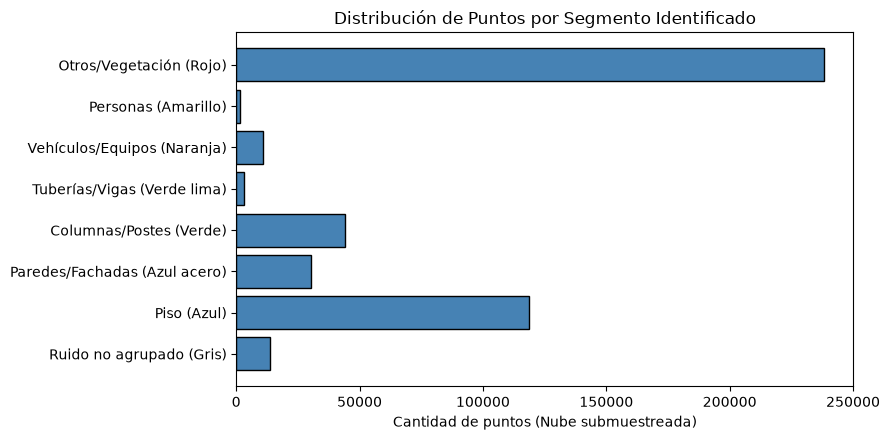

In [8]:
nombres_clases = {
    1: "Piso (Azul)",
    2: "Techo (Cian)",
    3: "Paredes/Fachadas (Azul acero)",
    4: "Columnas/Postes (Verde)",
    5: "Tuberías/Vigas (Verde lima)",
    6: "Vehículos/Equipos (Naranja)",
    7: "Personas (Amarillo)",
    8: "Otros/Vegetación (Rojo)",
    -1: "Ruido no agrupado (Gris)"
}

clases_unicas, conteos = np.unique(etiquetas, return_counts=True)

print(f"{'CLASE SEGMENTADA':<32} | {'PUNTOS (VOXEL)':<15} | {'PORCENTAJE':<10}")
print("-" * 65)
for c, cnt in zip(clases_unicas, conteos):
    pct = (cnt / n_puntos) * 100
    print(f"{nombres_clases.get(c, str(c)):<32} | {cnt:<15,} | {pct:>6.2f}%")

# El gráfico permite comparar de un vistazo el tamaño relativo de cada segmento.
plt.figure(figsize=(9, 4.5))
etiquetas_plot = [nombres_clases.get(c, str(c)) for c in clases_unicas]
plt.barh(etiquetas_plot, conteos, color='steelblue', edgecolor='black')
plt.xlabel("Cantidad de puntos (Nube submuestreada)")
plt.title("Distribución de Puntos por Segmento Identificado")
plt.tight_layout()
plt.savefig("estadisticas_segmentacion.png", dpi=300)
plt.show()

## Devolver los colores al escaneo completo

Cada punto original recibe el color del punto submuestreado más cercano. Así recuperamos la resolución del escaneo de entrada sin repetir todo el análisis sobre más de un millón de puntos. El resultado se escribe como PLY en `ARCHIVO_SALIDA`.

In [9]:
print(f"Propagando colores a los {len(pts_orig):,} puntos originales con KDTree...")
# Cada punto original toma el color de su vecino más cercano en la nube reducida.
tree = cKDTree(puntos)
_, idx_vecinos = tree.query(pts_orig, k=1, workers=-1)

colores_finales = colores_seg[idx_vecinos]
pcd_orig.colors = o3d.utility.Vector3dVector(colores_finales)

print(f"Exportando archivo final: {ARCHIVO_SALIDA}...")
# Guardamos el PLY en binario para que ocupe menos espacio.
o3d.io.write_point_cloud(ARCHIVO_SALIDA, pcd_orig, write_ascii=False)
print("¡Archivo exportado con éxito!")

Propagando colores a los 1,647,021 puntos originales con KDTree...
Exportando archivo final: FARO_Scan_Segmentado_Final.ply...
¡Archivo exportado con éxito!
